# TP 4 — Assembler et entraîner le modèle complet

Tokens (+ positions) → attention multi-têtes → LayerNorm + MLP → ×4 blocs résiduels → unembedding + softmax.

> Sur Colab : *Exécution → Modifier le type d'exécution → GPU*. Sur CPU tout tourne aussi (quelques minutes).

## Étape 0 — Préparer le notebook

In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)
torch.manual_seed(1337)

cpu


In [2]:
import os
from urllib.request import urlretrieve

if not os.path.exists("input.txt"):
    url = ("https://raw.githubusercontent.com/karpathy/"
           "char-rnn/master/data/tinyshakespeare/input.txt")
    urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]

def get_batch(split):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i:i + block_size] for i in ix])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

### Réponses
- **d_h** = n_embd / n_head = 64 / 4 = **16**.
- **Tokens par batch** : B × T = 16 × 32 = **512** tokens (donc 512 prédictions).
- **Sur CPU**, on réduit d'abord **`max_iters`** (ex. 500) pour un test rapide, puis éventuellement `eval_iters` (l'évaluation coûte 2×200 forwards toutes les 100 itérations).

## Étape 1 — Une tête

In [3]:
class Head(nn.Module):
    """Une tête d'auto-attention causale."""
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape                                   # (B,T,n_embd)
        k, q = self.key(x), self.query(x)                   # (B,T,hs)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5    # (B,T,T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)                                   # (B,T,hs)
        return wei @ v                                      # (B,T,hs)

h = Head(16).to(device)
print(h(torch.randn(16, 32, 64, device=device)).shape)

torch.Size([16, 32, 16])


### Réponses
- **`k.size(-1)` plutôt que C** : la variance de q·k dépend de la dimension du produit scalaire, c'est-à-dire **d_h = head_size** (16), pas de n_embd (64). Diviser par √C sous-normaliserait.
- **`tril[:T,:T]`** : le buffer est créé pour la taille max `block_size`, mais en génération (début de séquence) on a souvent T < block_size. On découpe le masque à la taille réelle pour que les formes correspondent.
- `register_buffer` : `tril` suit le modèle sur le GPU et est sauvegardé, mais n'est pas un paramètre entraînable.

## Étape 2 — Combiner plusieurs têtes

In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)  # 4 × (B,T,16) -> (B,T,64)
        return self.dropout(self.proj(out))                   # (B,T,64)

### Réponses
- **Concaténer sur la dernière dimension** : chaque tête produit des *features* différentes pour les mêmes (batch, position). On les juxtapose feature par feature ; concaténer sur T inventerait des positions qui n'existent pas.
- **n_embd non divisible par n_head** : `head_size = n_embd // n_head` arrondit, la concaténation fait `n_head·head_size < n_embd` et l'addition résiduelle `x + sa(x)` échoue (ou `proj` reçoit la mauvaise taille). D'où l'`assert`. (Ici j'ai mis `num_heads * head_size` en entrée de `proj`, ce qui évite le crash dans `proj`, mais pas le décalage avec le résiduel.)

## Étape 3 — Assembler un bloc

In [5]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """Communication (attention) puis calcul (MLP), en pré-norm + résiduel."""
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))     # communication entre tokens
        x = x + self.ffwd(self.ln2(x))   # calcul individuel par token
        return x

### Réponses
- **Ordre** : `LayerNorm → sous-couche → addition` (pré-norm) : `x = x + f(LN(x))`, d'abord pour l'attention, puis pour le MLP.
- **Communication** = l'**attention** (les tokens échangent de l'information selon les poids `wei`).
- **Calcul** = le **feed-forward** (chaque token « réfléchit » seul à ce qu'il a collecté).

## Étapes 4–6 — Modèle : couches, passage avant, génération

In [6]:
class BigramLanguageModel(nn.Module):  # (nom conservé du TP 1, mais c'est un mini-GPT)
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)       # (65, 64)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)    # (32, 64)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)                        # (64 -> 65)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)                           # (B,T,C)
        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(pos)                        # (T,C)

        x = tok_emb + pos_emb                                               # (B,T,C) broadcast
        x = self.blocks(x)                                                  # (B,T,C)
        x = self.ln_f(x)
        logits = self.lm_head(x)                                            # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B * T, vocab_size)
            targets = targets.reshape(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]          # au plus block_size tokens
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]                # (B,vocab_size)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

### Réponses
**Étape 4**
- Dimensions : `token_embedding_table` **(65, 64)**, `position_embedding_table` **(32, 64)**, `lm_head` poids **(65, 64)** + biais (65) — appliquée comme 64 → 65.
- **`lm_head` séparé** : au TP 1 la table faisait les deux rôles (C × C). Maintenant l'embedding donne une représentation interne de dimension n_embd, enrichie par 4 blocs ; il faut une projection distincte pour revenir au vocabulaire. Les deux matrices ont des rôles différents (entrée vs sortie) et des formes compatibles mais pas identiques (on pourrait les partager — *weight tying* — mais ce n'est pas obligatoire).

**Étape 5**
- **Broadcasting** : `(B,T,C) + (T,C)` → les dimensions sont alignées par la droite ; `(T,C)` est vu comme `(1,T,C)` et répété sur les B séquences. Toutes les séquences partagent les mêmes vecteurs de position.
- **Pas d'aplatissement en génération** : on a besoin de garder l'axe T pour extraire `logits[:, -1, :]` (dernière position) ; on n'aplatit que pour satisfaire `cross_entropy`.

**Étape 6**
- **`@torch.no_grad()`** : pas de rétropropagation en génération → on ne stocke pas le graphe de calcul : moins de mémoire, plus rapide.
- **`multinomial` plutôt qu'`argmax`** : `argmax` est déterministe et tombe vite dans des boucles répétitives (« the the the… »). Échantillonner respecte la distribution apprise et donne un texte varié.
- **`idx[:, -block_size:]`** : l'embedding de position n'a que `block_size` lignes ; au-delà, `position_embedding_table(pos)` planterait.

## Étapes 7 et 8 — Évaluer puis entraîner

In [7]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

def generate_text(n=2000):
    context = torch.zeros((1, 1), dtype=torch.long, device=device)
    return decode(model.generate(context, max_new_tokens=n)[0].tolist())

In [8]:
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M paramètres")
print("=== AVANT entraînement ===")
print(generate_text(300))

0.209729 M paramètres
=== AVANT entraînement ===



DuJAMJ3fX$VWoGCYngj$'onoE,$AT-NvynticCzJ-c!bnDNyjwND,?to;
VcANzq:nU$3NVAz:YzgNkceei.-efVhpXz,NApQe.3hRfNThglUzoecXgZ q.g?d
xeo$ug:'QmZqRzF!neLZmh.TW,$NJko.iu!seNwol$zJipJhwiKeo,Ssnu3blKpSpbMcSWhWmYn&UwNUc-qmfjkeRecJDeqqNWVa-?gLrR X&M ?BJxRlB;?zUC
blOHdJV
XXo;Vch.kt?Hpza:hoV.NarnDozmp zPj-!gTsoSN-FgA


In [9]:
import time
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
history = []
t0 = time.time()

for iteration in range(max_iters):
    if iteration % eval_interval == 0 or iteration == max_iters - 1:
        losses = estimate_loss()
        history.append((iteration, losses['train'], losses['val']))
        if iteration % 500 == 0 or iteration == max_iters - 1:
            print(f"step {iteration:5d} | train {losses['train']:.4f} | val {losses['val']:.4f} | {time.time()-t0:.0f}s")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step     0 | train 4.4051 | val 4.4002 | 3s


step   500 | train 2.2637 | val 2.2648 | 27s


step  1000 | train 2.0544 | val 2.0980 | 51s


step  1500 | train 1.9380 | val 2.0183 | 75s


step  2000 | train 1.8572 | val 1.9611 | 99s


...

step  3000 | train 1.7662 | val 1.9129 | 147s


step  3500 | train 1.7283 | val 1.8849 | 171s


step  4000 | train 1.6999 | val 1.8575 | 195s


step  4500 | train 1.6679 | val 1.8289 | 220s


step  4999 | train 1.6634 | val 1.8247 | 247s


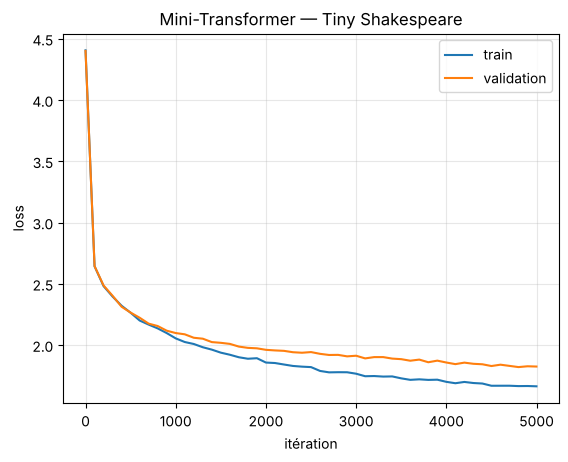

In [10]:
import matplotlib.pyplot as plt
it, tr, va = zip(*history)
plt.plot(it, tr, label="train"); plt.plot(it, va, label="validation")
plt.xlabel("itération"); plt.ylabel("loss"); plt.legend(); plt.grid(alpha=.3)
plt.title("Mini-Transformer — Tiny Shakespeare"); plt.show()

### Réponses
- **`model.eval()` / `model.train()`** : `eval()` désactive le dropout (et figerait une BatchNorm) pour mesurer le modèle de façon déterministe ; `train()` le réactive avant de reprendre l'apprentissage. (Avec `dropout = 0.0` ça ne change rien ici, mais c'est la bonne pratique.)
- **Loss train ↓ mais val ↑** : **surapprentissage** — le modèle mémorise le corpus d'entraînement au lieu de généraliser. Remèdes : plus de dropout, modèle plus petit, early stopping (garder le checkpoint au minimum de la val), plus de données.

## Étape 9 — Générer et expérimenter

In [11]:
print("=== APRÈS entraînement ===")
print(generate_text(2000))

=== APRÈS entraînement ===



she passince, vour hear weret, and to go the rience, and a did and reticit,
O have drerbacwicy that broth.

Romon:
What's with your say me be at intin the Latch,
What arm who painson of Edwecomb the drome more exer mayly you hum.
Third Fallimes much all at nee thre I had be,
Nothaved arther prome at make compour'd that him;
Or by the did your houth. But again I have long.

ISABELLANGE:
Tho shall still coursent to him couttased
sender hither in Bititty out die!

MARCILIS:
Nad sir.

ISAGEL:
So let withman, but tereshat dimpone:
No I crity thrihers and wilt tent: I with like a seep a fast,-weath--back he him and you,
No shauffict that never he play,
Of, here the had seing, then.
Seem. When him I dry a bluish of father whose of my lord,
Which in hear Care his you will been, him other time 'twickinness for that thy than blambsting. jublet his would do him;
Of mourder him this will his at
in highneather daylebance, that Legion with betters man beting in day;
The seof this seen of knows, the

### Expériences

Les classes lisent les variables globales (`block_size`, `n_head`, …) à leur construction : on les modifie, on recrée le modèle, et on entraîne une version courte (1 500 itérations) pour comparer à budget égal.

In [12]:
def run(label, iters=1500, **overrides):
    global block_size, n_head, dropout, model
    saved = dict(block_size=block_size, n_head=n_head, dropout=dropout)
    globals().update(overrides)
    torch.manual_seed(1337)
    model = BigramLanguageModel().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    t0 = time.time()
    for _ in range(iters):
        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    l = estimate_loss()
    print(f"{label:28s} | params {sum(p.numel() for p in model.parameters())/1e3:6.1f}k | train {l['train']:.3f} | val {l['val']:.3f} | {time.time()-t0:4.0f}s")
    globals().update(saved)
    return l

results = {}
results["référence (T=32, 4 têtes)"] = run("référence (T=32, 4 têtes)")
results["block_size=16"] = run("block_size=16", block_size=16)
results["block_size=64"] = run("block_size=64", block_size=64)
results["1 tête (d_h=64)"] = run("1 tête (d_h=64)", n_head=1)
results["dropout=0.2"] = run("dropout=0.2", dropout=0.2)

référence (T=32, 4 têtes)    | params  209.7k | train 1.938 | val 2.008 |   38s


block_size=16                | params  208.7k | train 1.982 | val 2.062 |   28s


block_size=64                | params  211.8k | train 1.928 | val 2.008 |   55s


1 tête (d_h=64)              | params  209.7k | train 1.916 | val 2.009 |   26s


dropout=0.2                  | params  209.7k | train 2.060 | val 2.089 |   51s


### Interprétation des expériences
- **block_size** : à 16, la val est nettement moins bonne (≈ 2,06 contre 2,01) : moins de passé disponible. À 64, à budget court (1 500 itérations), pas de gain visible (≈ 2,01) pour ~1,5× plus de temps : le petit modèle n'a pas encore appris à exploiter un contexte si long. Le gain apparaît avec plus d'itérations / un modèle plus gros. Coût : l'attention est en O(T²).
- **1 tête vs 4 têtes** (n_embd constant, donc même nombre de paramètres) : résultats quasi identiques ici (val ≈ 2,01 dans les deux cas). En théorie, plusieurs têtes permettent de regarder **plusieurs choses à la fois** (ex. le caractère précédent *et* le début du mot), mais avec ~0,2 M paramètres et 1 500 itérations l'effet est noyé dans le bruit.
- **Dropout** : à 1 500 itérations il n'y a pas de surapprentissage (train ≈ val), donc dropout=0,2 ralentit l'apprentissage (val 2,09). Sur l'entraînement complet, l'écart train/val passe de 0 à ~0,16 (1,66 vs 1,82) : c'est là qu'un léger dropout commencerait à servir. Il devient utile quand l'écart train/val se creuse (modèle plus gros, entraînement plus long).
- **Entraînement complet** : loss 4,40 → train 1,66 / val 1,82 en 5 000 itérations (bien mieux que le plafond ~2,45 du bigramme).
- **Texte généré** : on reconnaît la **structure** d'une pièce (noms en majuscules suivis de `:`, répliques, retours à la ligne, mots anglais courts plausibles) sans que le sens soit correct — c'est le résultat attendu pour ~0,2 M paramètres.

## Bilan des quatre TP

| Classe / opération | Notion du cours | Rôle |
|---|---|---|
| `token_embedding_table` | embedding (W_E) | identité du caractère → vecteur |
| `position_embedding_table` | encodage positionnel | place dans le contexte (l'attention seule est invariante à l'ordre) |
| `Head` / `MultiHeadAttention` | auto-attention causale, Q/K/V | **crée le contexte** : fait communiquer les tokens |
| `FeedForward` | MLP | **transforme chaque token** individuellement |
| `LayerNorm` + `x + …` | normalisation, résiduel | stabilité et flux du gradient |
| `ln_f` + `lm_head` | unembedding (W_U) | **produit les logits** sur le vocabulaire |
| `F.softmax` + `multinomial` | distribution de sortie | génération autorégressive |
| `F.cross_entropy` + `loss.backward()` | objectif de prédiction du token suivant | **la loss agit sur tout le modèle** : le gradient remonte à travers lm_head, chaque bloc (via les résiduels) jusqu'aux deux tables d'embedding |